# 8. The whole pipeline on a real song

This notebook runs every stage from notebooks 1–7, in order, on a **real recording** of voice + guitar, and
shows what each stage finds. It mirrors `pipeline.process`, which is what the app and the command line call.
For everyday use you'd simply run:

```bash
uv run songpolish my_song.m4a --pitch-mode key --targeting phrase
```

**Set `SONG` below to your own recording** (any common format: wav, mp3, m4a…). The voice/guitar separation
takes a few minutes the first time and is then cached in `notebooks/.cache/`. By default no audio of your
song is embedded in the notebook (it would make the file large and contain your recording); set
`PLAY = True` to get players.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

from pathlib import Path
SONG = Path("~/Downloads/El veranito gallego.m4a").expanduser()   # <- your recording
OUT = Path("~/Downloads/polished/notebook_demo").expanduser()       # results are written here
PLAY = False                                                         # True: embed audio players
CACHE = Path(".cache"); CACHE.mkdir(exist_ok=True)
assert SONG.is_file(), f"Set SONG to a recording that exists (not found: {SONG})"

def listen(audio, label, start_s=0, seconds=20):
    if PLAY:
        play(np.atleast_2d(audio)[:, int(start_s * SR): int((start_s + seconds) * SR)], label=label)
clock = lambda s: f"{int(s // 60)}:{s % 60:04.1f}"

## Step 1: load

`audio_io.load` reads the file (falling back to the ffmpeg bundled with `imageio-ffmpeg` for AAC/m4a, which
the main audio library can't decode on Linux), resamples to 44.1 kHz and returns `(channels, samples)`.

In [2]:
from songpolish.audio_io import load
from songpolish.analysis import loudness_lufs
take = load(SONG)
print(f"{SONG.name}: shape {take.shape}, {take.shape[1] / SR:.1f} s, loudness {loudness_lufs(take):.1f} LUFS")
listen(take, "the recording (first 20 s)")

El veranito gallego.m4a: shape (1, 10637312), 241.2 s, loudness -21.2 LUFS


## Step 2: separate voice and guitar (notebook 6)

Demucs splits the take into a vocal stem and an accompaniment stem. Cached after the first run.

In [3]:
import time
from songpolish import separation
cache = CACHE / f"{SONG.stem}_stems.npz"
if cache.is_file():
    d = np.load(cache); vocal, guitar = d["vocal"], d["guitar"]
    print("stems loaded from", cache)
else:
    t0 = time.time()
    stems = separation.separate(take, SR)
    vocal, guitar = stems.vocals, stems.accompaniment
    np.savez(cache, vocal=vocal, guitar=guitar)
    print(f"separated in {time.time() - t0:.0f} s, cached in {cache}")
print(f"vocal stem {loudness_lufs(vocal):.1f} LUFS, guitar stem {loudness_lufs(guitar):.1f} LUFS")

stems loaded from .cache/El veranito gallego_stems.npz


vocal stem -23.6 LUFS, guitar stem -19.1 LUFS


## Step 3: tuning reference, chords and keys (notebook 2)

The guitar sets the reference: its tuning offset, its chroma over time, and the key(s) with any modulation.

guitar tuning: +1.0 cents from A=440
keys over time: 0:00.0 A major, 3:19.9 A minor


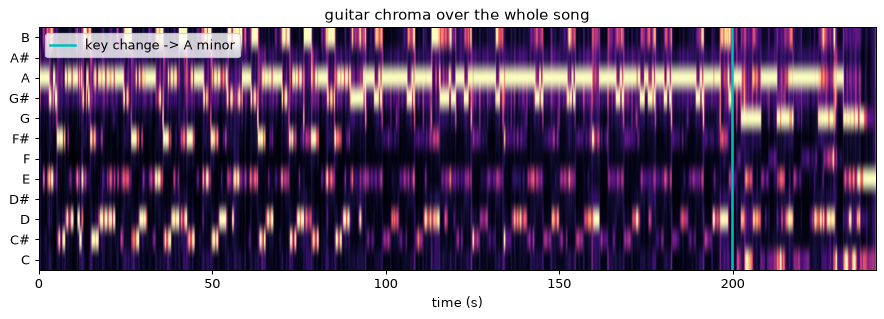

In [4]:
from songpolish.analysis import tuning_offset_cents, harmony_map, HARMONY_HOP
offset = tuning_offset_cents(guitar)
h = harmony_map(guitar, SR, tuning_cents=offset)
print(f"guitar tuning: {offset:+.1f} cents from A=440")
print("keys over time:", ", ".join(f"{clock(s.start / SR)} {s.key.name}" for s in h.keys))
fig, ax = plt.subplots(figsize=(12, 3.5))
tmax = h.chroma.shape[1] * HARMONY_HOP / SR
ax.imshow(h.chroma, aspect="auto", origin="lower", extent=[0, tmax, -0.5, 11.5], cmap="magma")
for s in h.keys[1:]: ax.axvline(s.start / SR, color="c", lw=2, label=f"key change -> {s.key.name}")
ax.set_yticks(range(12)); ax.set_yticklabels(NOTE_NAMES); ax.set_xlabel("time (s)")
ax.set_title("guitar chroma over the whole song"); ax.legend(loc="upper left") if len(h.keys) > 1 else None
plt.show()

If one row is bright almost everywhere (on the song this was developed on, A), something rings through
the whole song: a drone, such as an open string. Notebook 2 explains why that matters.

## Step 4: find the sung notes (notebook 3)

346 sung notes (after dropping phantoms more than 30 dB below the singing)
median length 0.23 s; 68 notes longer than 0.5 s
distance from the nearest semitone: mean |error| 21 cents, mean +2 (positive = sharp)


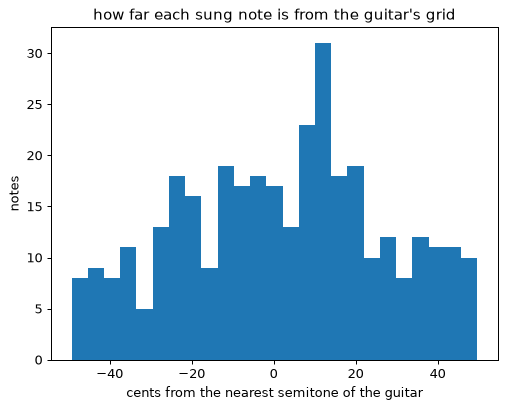

In [5]:
from songpolish.pitch import detect_notes, PHANTOM_DB
notes = detect_notes(vocal, offset, SR)
lengths = np.array([(n.end - n.start) / SR for n in notes])
cents = np.array([100 * (n.pitch - round(n.pitch)) for n in notes])
print(f"{len(notes)} sung notes (after dropping phantoms more than {PHANTOM_DB:.0f} dB below the singing)")
print(f"median length {np.median(lengths):.2f} s; {np.sum(lengths > 0.5)} notes longer than 0.5 s")
print(f"distance from the nearest semitone: mean |error| {np.mean(np.abs(cents)):.0f} cents, mean {np.mean(cents):+.0f} (positive = sharp)")
plt.hist(cents, bins=25); plt.xlabel("cents from the nearest semitone of the guitar"); plt.ylabel("notes")
plt.title("how far each sung note is from the guitar's grid"); plt.show()

A singer who is in tune but imprecise gives a histogram centred on 0. A shifted centre means the voice sits
sharp or flat against the guitar as a whole, and a flat, wide histogram (lots of notes near ±50 cents) means
"nearest semitone" is often a coin toss, which is where chords and key have to decide (notebook 4).

## Step 5: choose the targets (notebook 4)

We compare the gentle default (NEAREST, chord-aware) with the combination the musician preferred
(PHRASE + strict key, including repeats in a new key).

In [6]:
from songpolish.melody import TargetStrategy, choose_targets
allowed = [h.key_at(n.start, n.end).pitch_classes for n in notes]           # strict key: the key *at that moment*
t_default = choose_targets(notes, TargetStrategy.NEAREST, h)
t_strict = choose_targets(notes, TargetStrategy.PHRASE, h, allowed)
moved = lambda ts: sum(t != round(n.pitch) for t, n in zip(ts, notes))
print(f"notes moved to a different note than the nearest one: default {moved(t_default)}, phrase + strict key {moved(t_strict)}")
in_key = lambda ts: np.mean([int(t) % 12 in h.key_at(n.start, n.end).pitch_classes for t, n in zip(ts, notes)])
print(f"targets in the key of the moment: sung (nearest) {in_key([round(n.pitch) for n in notes]):.0%}, "
      f"default {in_key(t_default):.0%}, phrase + strict {in_key(t_strict):.0%}")

notes moved to a different note than the nearest one: default 82, phrase + strict key 180
targets in the key of the moment: sung (nearest) 59%, default 82%, phrase + strict 100%


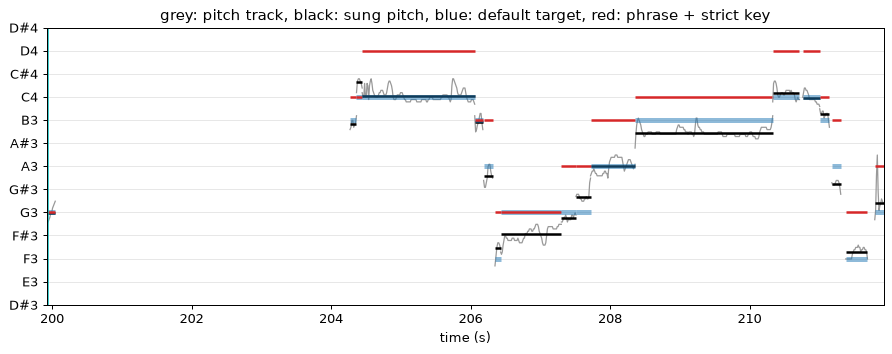

In [7]:
# A closer look: 12 seconds around the key change (or the middle of the song if there is none)
centre = h.keys[1].start / SR + 6 if len(h.keys) > 1 else take.shape[1] / SR / 2
a, b = centre - 6, centre + 6
fig, ax = plt.subplots(figsize=(12, 4))
for n, td, ts in zip(notes, t_default, t_strict):
    s, e = n.start / SR, n.end / SR
    if e < a or s > b: continue
    ax.plot(np.linspace(s, e, len(n.frames)), n.frames, color="0.6", lw=1)
    ax.hlines(n.pitch, s, e, color="k", lw=2)
    ax.hlines(td, s, e, color="C0", lw=4, alpha=0.5)
    ax.hlines(ts, s, e, color="C3", lw=2)
for s in h.keys[1:]: ax.axvline(s.start / SR, color="c", lw=2)
shown = [(n, td, ts) for n, td, ts in zip(notes, t_default, t_strict) if a < n.start / SR < b]
lo = int(min(min(min(n.frames), td, ts) for n, td, ts in shown)) - 1
hi = int(max(max(max(n.frames), td, ts) for n, td, ts in shown)) + 2
ax.set_yticks(range(lo, hi)); ax.set_yticklabels([note_name(m) for m in range(lo, hi)]); ax.grid(axis="y", alpha=0.3)
ax.set_xlim(a, b); ax.set_xlabel("time (s)")
ax.set_title("grey: pitch track, black: sung pitch, blue: default target, red: phrase + strict key")
plt.show()

## Step 6: plan the shifts, reclaim the leaked voice, render (notebooks 5 and 6)

In [8]:
from songpolish.pitch import plan_corrections, reclaim_leakage, apply_corrections
t0 = time.time()
shifts, report = plan_corrections(vocal, 0.8, offset, h.key, h, SR, TargetStrategy.PHRASE, notes)
print(report.summary())
vocal_r, guitar_r, reclaimed = reclaim_leakage(vocal, guitar, notes, shifts, offset, SR)
print(f"voice reclaimed from the guitar stem on {reclaimed} moved notes")
corrected = apply_corrections(vocal_r, shifts, 0.0, SR)
print(f"rendered {len(shifts)} note shifts in {time.time() - t0:.0f} s")

309/346 notes nudged; average error 68 cents, average shift 73 cents. 180 notes moved to a different (right) note.


voice reclaimed from the guitar stem on 180 moved notes


rendered 309 note shifts in 48 s


## Step 7: recording + correction, tone chain, master (notebooks 6 and 7)

In [9]:
from songpolish.pipeline import with_correction
from songpolish import tone, mastering
from songpolish.settings import Settings, PitchMode
from songpolish.audio_io import save
settings = Settings(pitch_mode=PitchMode.KEY, note_targeting=TargetStrategy.PHRASE)
mixed = with_correction(take, vocal_r, corrected, settings.vocal_balance_db)
changed = np.mean(np.any(mixed != take, axis=0))
print(f"samples changed by the pitch correction: {changed:.1%} of the song (the rest is the recording, bit for bit)")
polished = tone.process_source(mixed, tone.Source.MIX, settings)
polished = mastering.add_space(polished, 0.5 * settings.reverb, vocal=False)
polished = mastering.master(polished, settings.target_lufs, settings.true_peak_db, glue=settings.compression)
reference = mastering.loudness_match(take, loudness_lufs(polished), settings.true_peak_db)
OUT.mkdir(parents=True, exist_ok=True)
print("polished:  ", save(OUT / f"{SONG.stem}_polished.wav", polished))
print("reference: ", save(OUT / f"{SONG.stem}_original_matched.wav", reference))
print(f"loudness: {loudness_lufs(take):.1f} -> {loudness_lufs(polished):.1f} LUFS")
listen(reference, "original (same loudness)", start_s=centre - 10)
listen(polished, "polished", start_s=centre - 10)

samples changed by the pitch correction: 50.3% of the song (the rest is the recording, bit for bit)


polished:   /home/jj/Downloads/polished/notebook_demo/El veranito gallego_polished.wav


reference:  /home/jj/Downloads/polished/notebook_demo/El veranito gallego_original_matched.wav


loudness: -21.2 -> -14.0 LUFS


## What to check by ear

Numbers can't hear. When listening to the result (best: original and polished at the same loudness, as saved
above), these are the questions that found every real problem so far:

* **Does any note sound robotic, doubled or "fluttery"?** (notebook 5: pitch-shifter artefacts; notebook 6:
  leakage.) Note the time.
* **Is there hiss or "old recorder" sound that wasn't in the original?** (notebook 7: EQ and noise.)
* **Does the melody go where it should?** Ask a musician, especially after key changes (notebook 4).
* **Does the guitar sound the same as in the original?** It should: outside corrected notes, the song *is* the
  recording (notebook 6).

For each issue, the matching notebook shows how to measure it on your own file.